# Medical Insurance Cost Prediction - Model Evaluation

In this notebook, we will evaluate the performance of our trained models:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Neural Network

We will:
- Load the trained models
- Make predictions on the test set
- Create various visualizations to compare model performance
- Analyze prediction errors
- Identify the best performing model


In [1]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
# import joblib

# # Set style for better visualizations
# plt.style.use('default')

# # Load the processed data
# processed_data = pd.read_csv('../data/processed/insurance_processed.csv')

# # Separate features and target
# y = processed_data['charges']
# X = processed_data.drop('charges', axis=1)

# ##### اینجا مقایسه رو کل داده انجام شده ولی جمنای میگه که داده باید دوباده تقسیم بشه

# # Load all models
# models = {
#     'Linear Regression': joblib.load('../models/linear_regression.joblib'),
#     'Decision Tree': joblib.load('../models/decision_tree.joblib'),
#     'Random Forest': joblib.load('../models/random_forest.joblib'),
#     'Neural Network': joblib.load('../models/neural_network.joblib')
# }

# # Make predictions with all models
# predictions = {name: model.predict(X) for name, model in models.items()}


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split # اضافه شد
import joblib

# تنظیم استایل
plt.style.use('default')

# ۱. لود کردن داده‌ها
processed_data = pd.read_csv('../data/processed/insurance_test_scaled.csv')

# ۲. جداسازی ویژگی‌ها و هدف
y_test = processed_data['charges']
X_test = processed_data.drop('charges', axis=1)


# ۴. لود کردن مدل‌ها
models = {
    'Linear Regression': joblib.load('../models/linear_regression.joblib'),
    'Decision Tree': joblib.load('../models/decision_tree.joblib'),
    'Random Forest': joblib.load('../models/random_forest.joblib')
}


# ۵. پیش‌بینی فقط روی داده‌های تست (X_test)
predictions = {name: model.predict(X_test) for name, model in models.items()}

# حالا از اینجا به بعد، تمام محاسبات متریک‌ها باید با y_test انجام شود

## 1. Model Performance Metrics

Let's calculate and compare various performance metrics for each model:
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R² Score


Model Performance Metrics:
            Model          MSE      RMSE       MAE     R2
Linear Regression 3.616439e+07 6013.6833 4259.1700 0.8032
    Decision Tree 1.999233e+07 4471.2787 2650.8977 0.8912
    Random Forest 1.790052e+07 4230.9004 2391.3072 0.9026


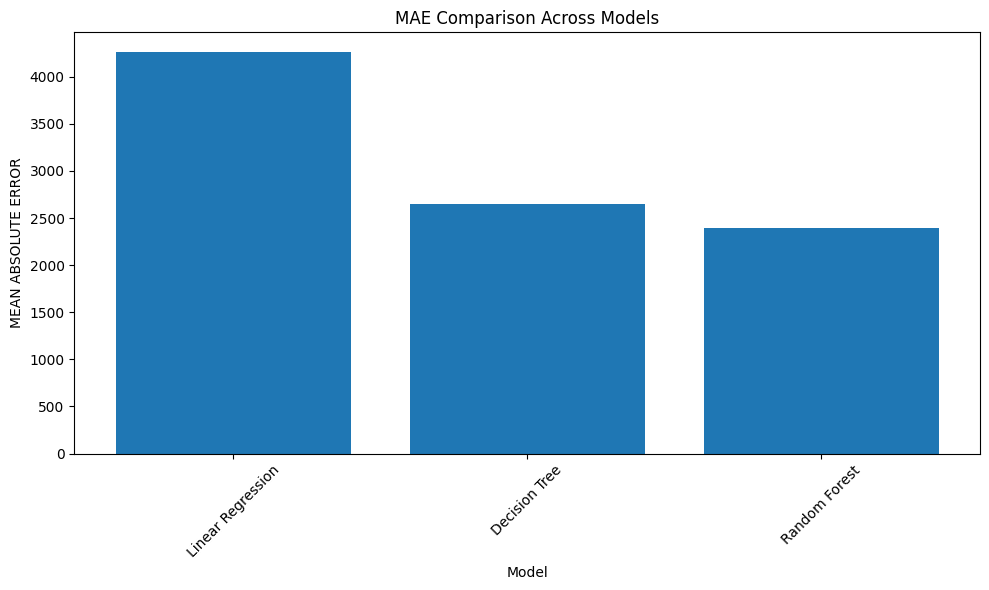

In [13]:
# Calculate metrics for each model
metrics = {
    'Model': [],
    'MSE': [],
    'RMSE': [],
    'MAE': [],
    'R2': []
}

for name, pred in predictions.items():
    metrics['Model'].append(name)
    mse = mean_squared_error(y_test, pred)
    metrics['MSE'].append(mse)
    metrics['RMSE'].append(np.sqrt(mse))
    metrics['MAE'].append(mean_absolute_error(y_test, pred))
    metrics['R2'].append(r2_score(y_test, pred))

# Create metrics dataframe
metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.round(4)

print("Model Performance Metrics:")
print(metrics_df.to_string(index=False))

# Create bar plot for RMSE comparison
plt.figure(figsize=(10, 6))
plt.bar(metrics_df['Model'], metrics_df['MAE'])
plt.title('MAE Comparison Across Models')
plt.xlabel('Model')
plt.ylabel('MEAN ABSOLUTE ERROR')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 2. Actual vs Predicted Values

Let's create scatter plots comparing actual vs predicted values for each model.


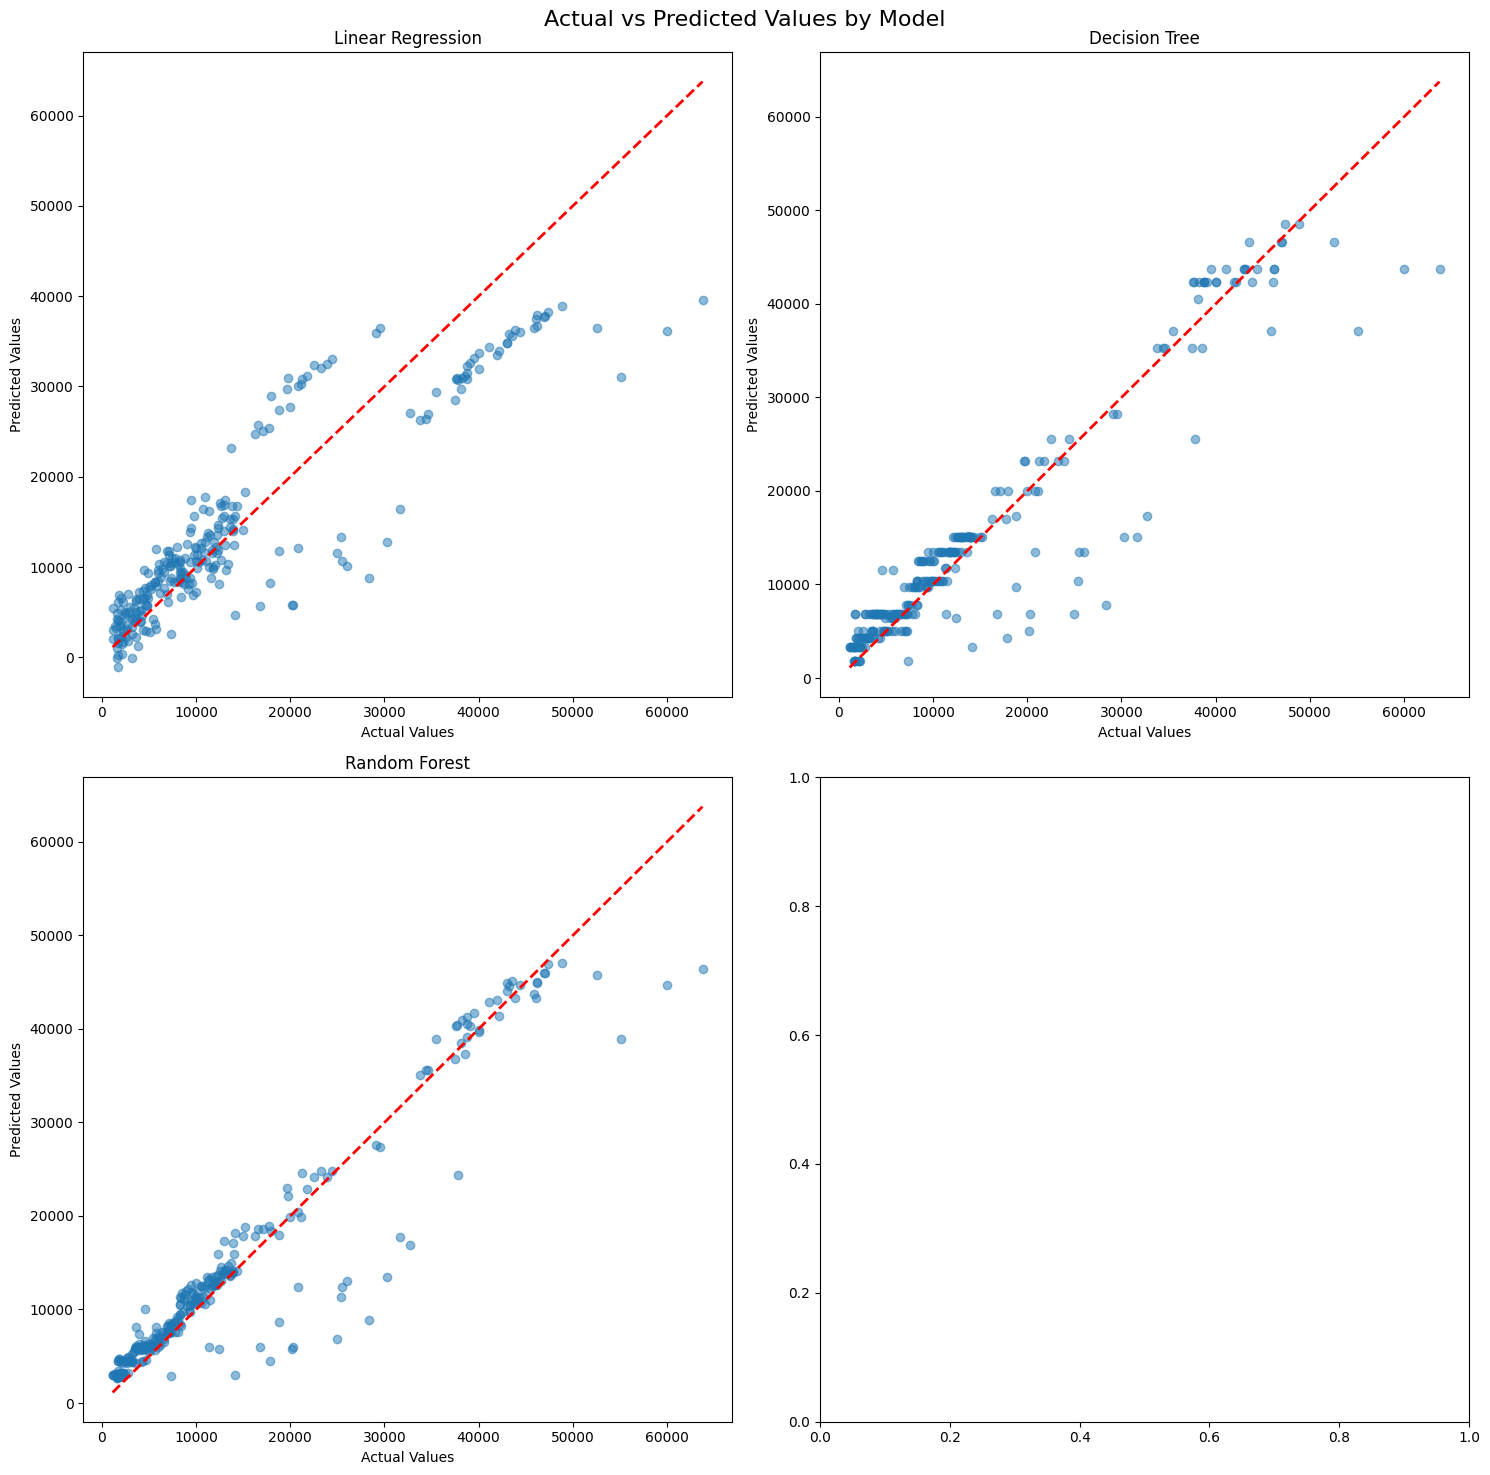

In [14]:
# Create scatter plots for actual vs predicted values
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
fig.suptitle('Actual vs Predicted Values by Model', fontsize=16)

for (name, pred), ax in zip(predictions.items(), axes.ravel()):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_title(name)
    ax.set_xlabel('Actual Values')
    ax.set_ylabel('Predicted Values')

plt.tight_layout()
plt.show()


## 3. Residual Analysis

Let's analyze the residuals (prediction errors) for each model to check for any patterns or biases.


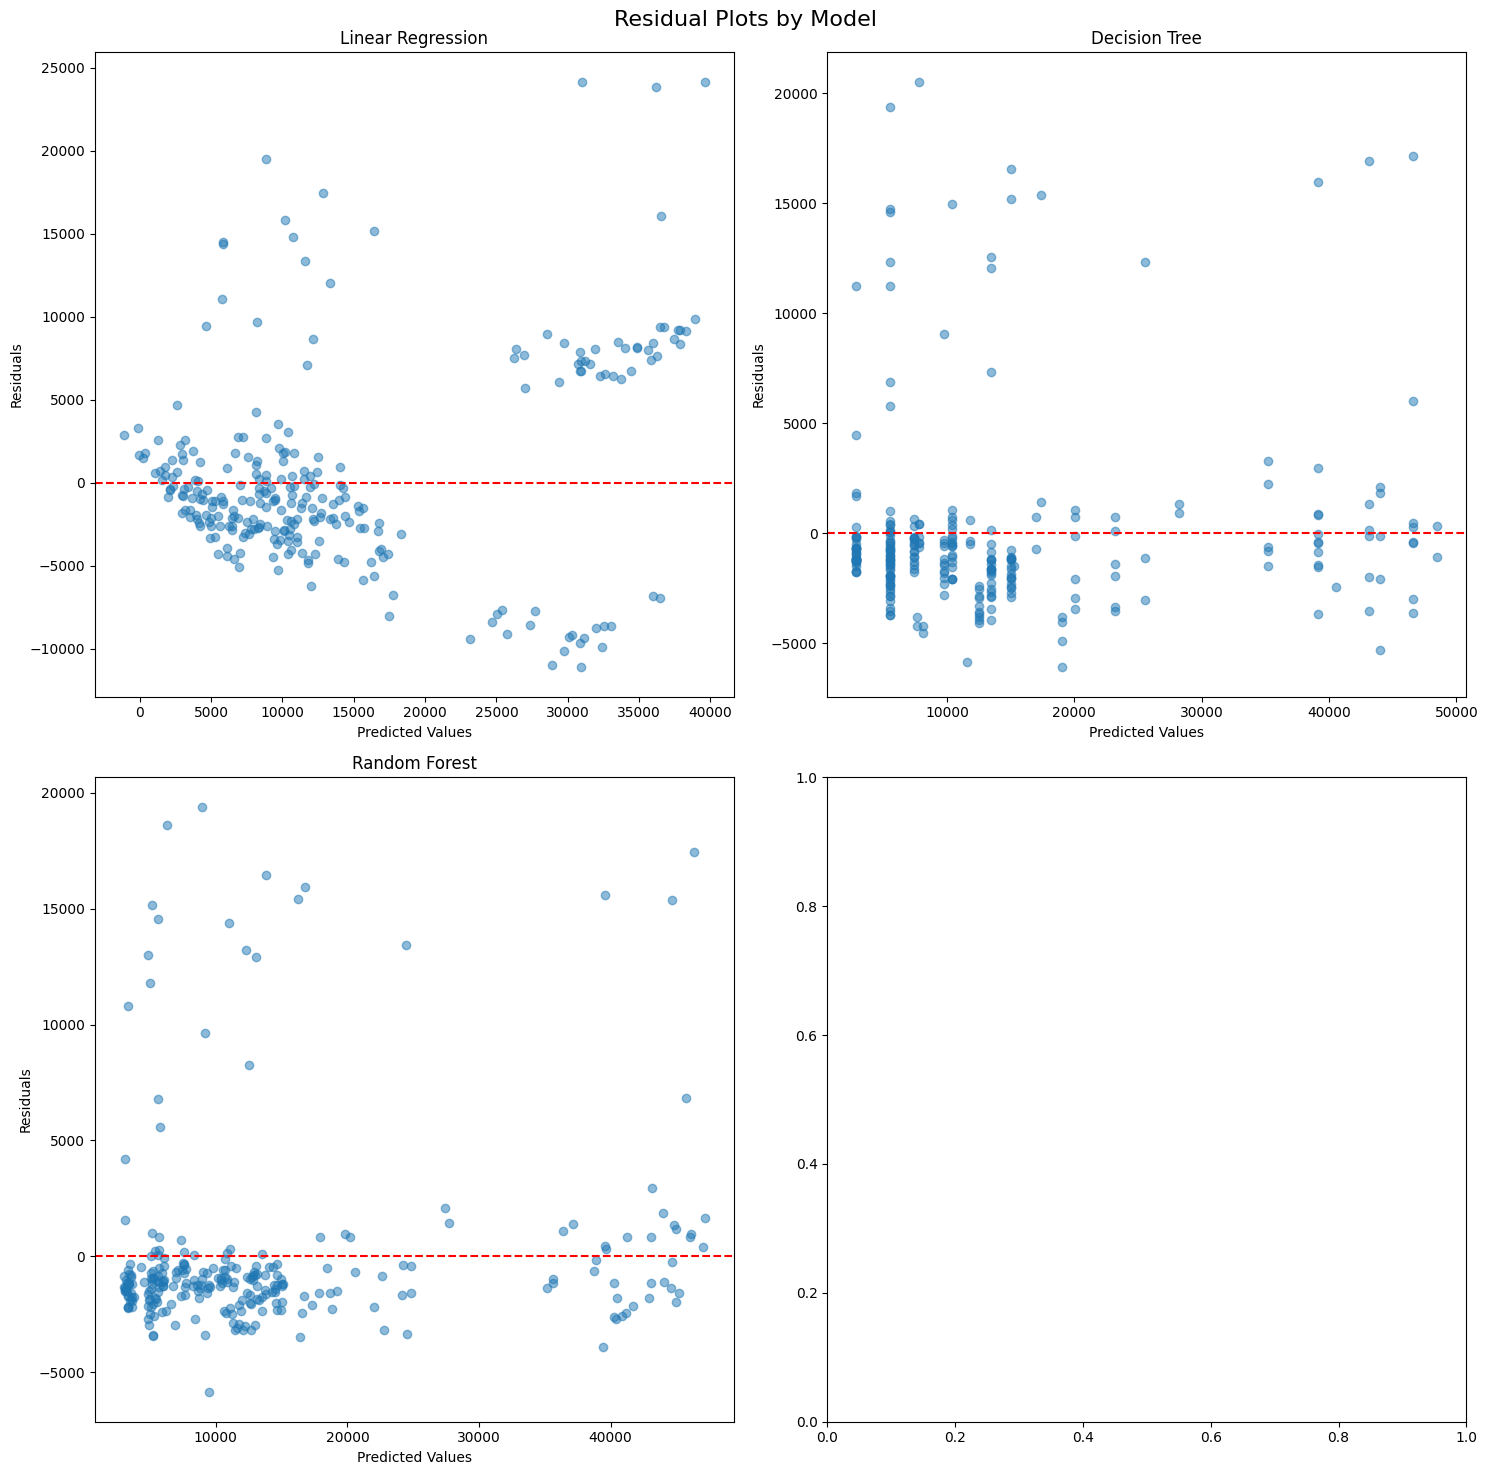

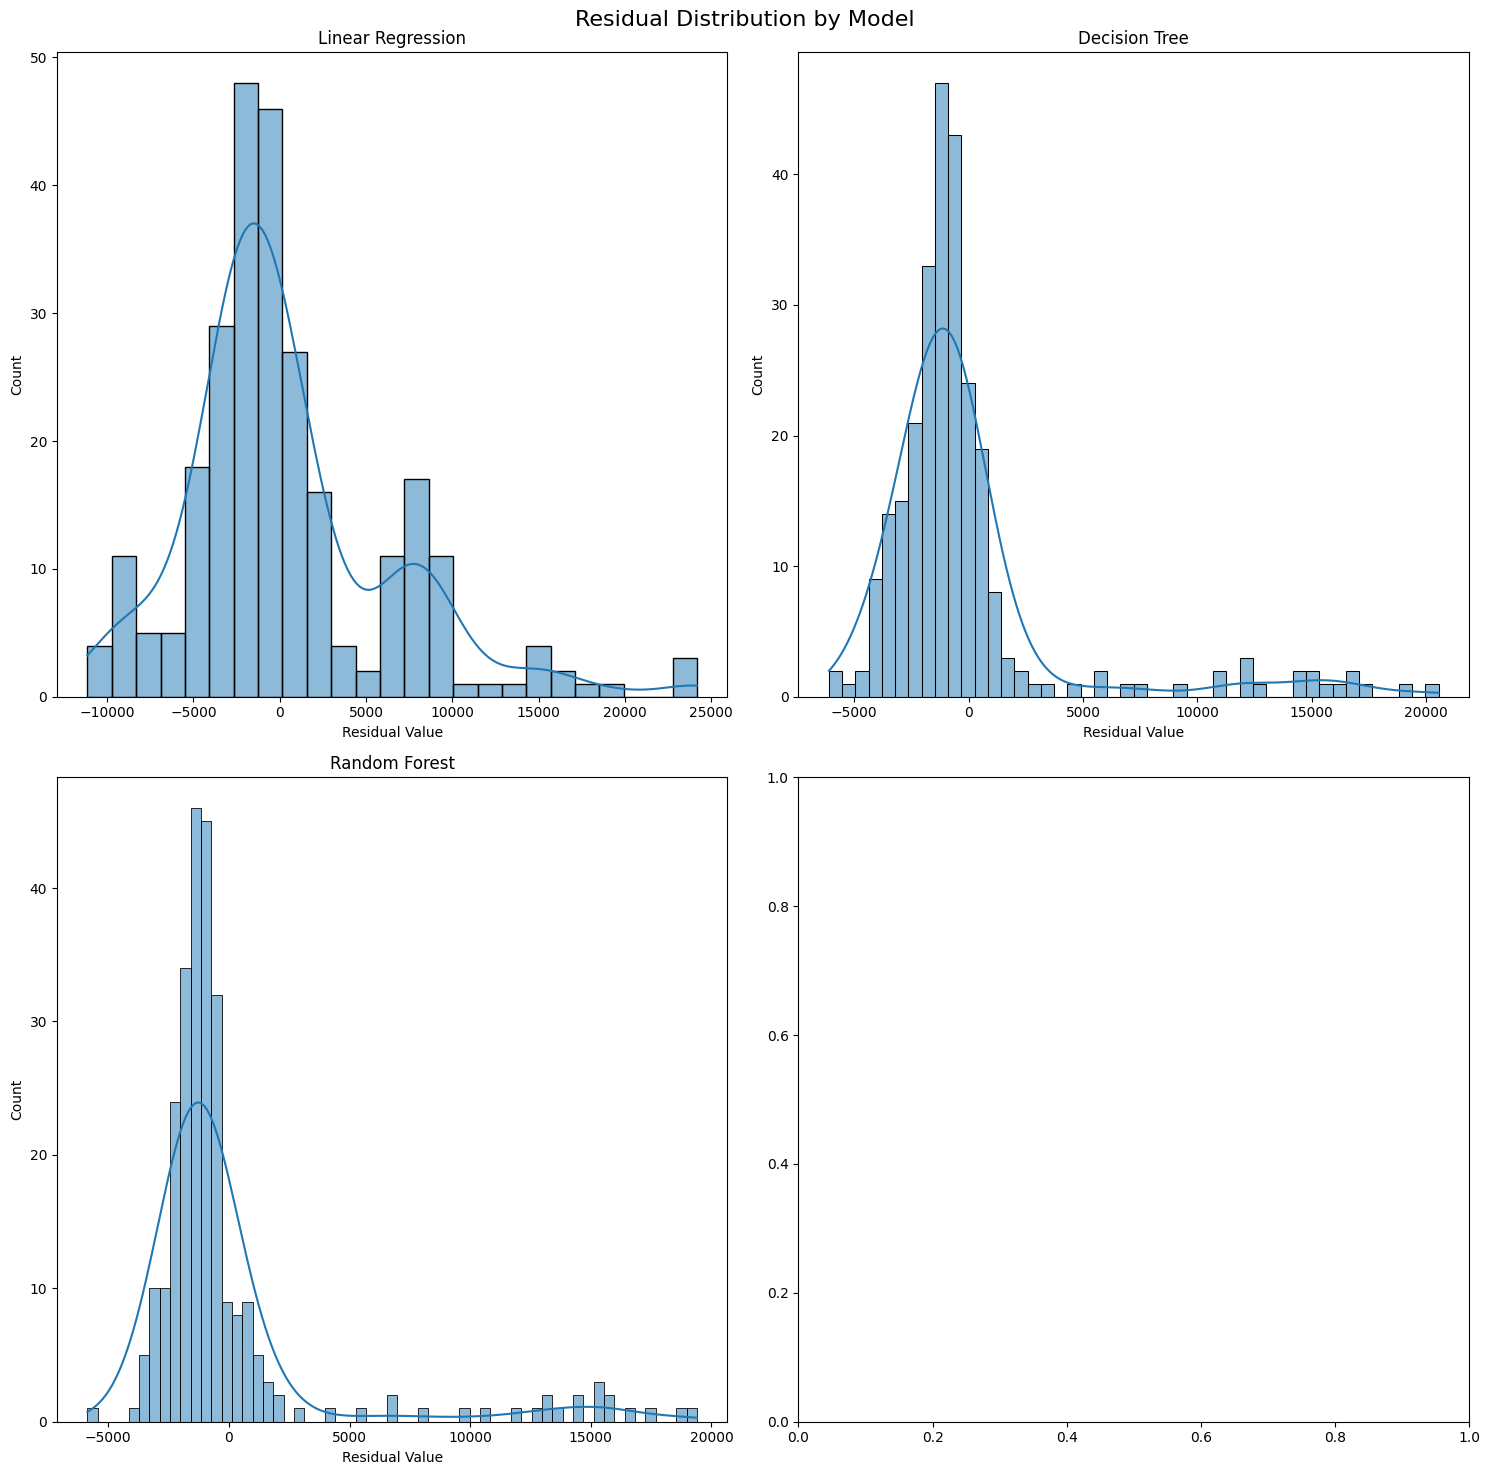

In [5]:
# Calculate residuals for each model
residuals = {name: y_test - pred for name, pred in predictions.items()}

# Create residual plots
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
fig.suptitle('Residual Plots by Model', fontsize=16)

for (name, resid), ax in zip(residuals.items(), axes.ravel()):
    ax.scatter(predictions[name], resid, alpha=0.5)
    ax.axhline(y=0, color='r', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Predicted Values')
    ax.set_ylabel('Residuals')

plt.tight_layout()
plt.show()

# Create residual distribution plots
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
fig.suptitle('Residual Distribution by Model', fontsize=16)

for (name, resid), ax in zip(residuals.items(), axes.ravel()):
    sns.histplot(resid, kde=True, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Residual Value')
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()


## 4. Feature Importance Analysis

For the tree-based models (Decision Tree and Random Forest), let's analyze feature importance to understand which factors most influence insurance charges.


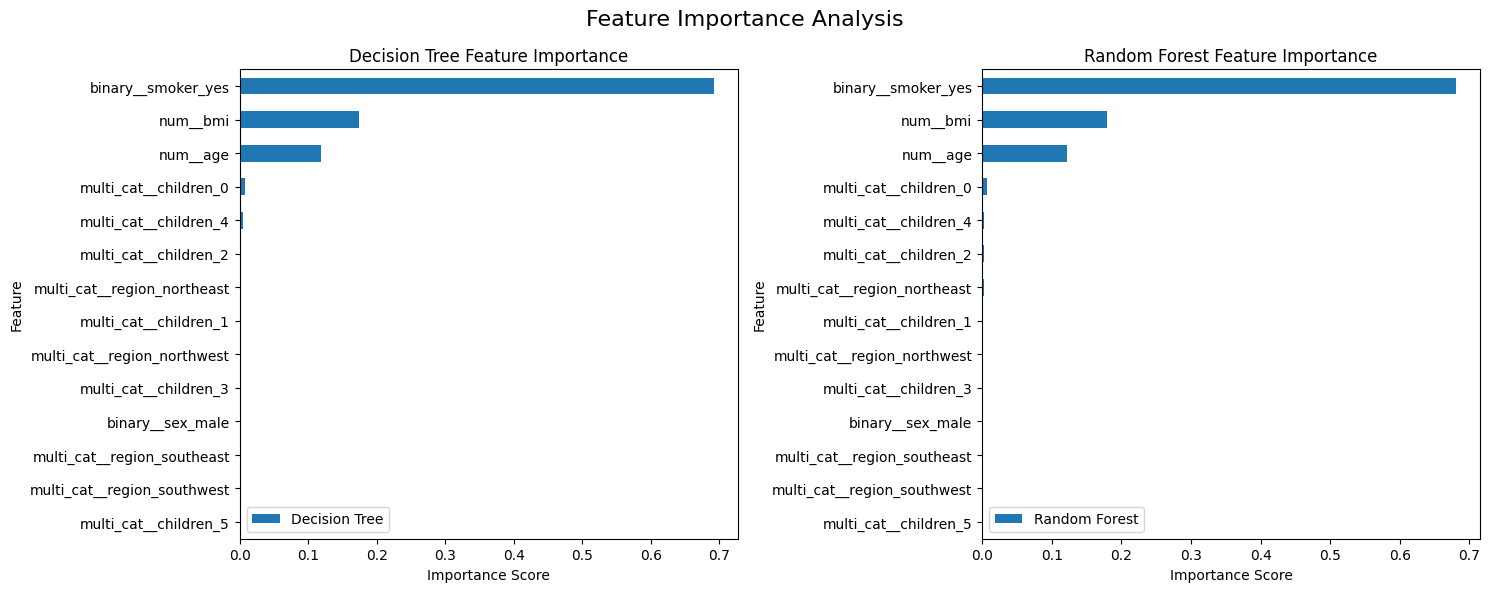


Feature Importance Rankings:
                    Feature  Decision Tree  Random Forest
      multi_cat__children_5         0.0000         0.0000
multi_cat__region_southwest         0.0019         0.0006
multi_cat__region_southeast         0.0000         0.0007
           binary__sex_male         0.0000         0.0007
      multi_cat__children_3         0.0000         0.0008
multi_cat__region_northwest         0.0000         0.0009
      multi_cat__children_1         0.0004         0.0015
multi_cat__region_northeast         0.0000         0.0020
      multi_cat__children_2         0.0000         0.0022
      multi_cat__children_4         0.0056         0.0025
      multi_cat__children_0         0.0080         0.0065
                   num__age         0.1189         0.1215
                   num__bmi         0.1735         0.1788
         binary__smoker_yes         0.6917         0.6812


In [16]:
# Get feature importance from tree-based models
feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Decision Tree': models['Decision Tree'].feature_importances_,
    'Random Forest': models['Random Forest'].feature_importances_
})

# Sort by Random Forest importance
feature_importance = feature_importance.sort_values('Random Forest', ascending=True)

# Create feature importance plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Feature Importance Analysis', fontsize=16)

# Decision Tree
feature_importance.plot(x='Feature', y='Decision Tree', kind='barh', ax=ax1)
ax1.set_title('Decision Tree Feature Importance')
ax1.set_xlabel('Importance Score')

# Random Forest
feature_importance.plot(x='Feature', y='Random Forest', kind='barh', ax=ax2)
ax2.set_title('Random Forest Feature Importance')
ax2.set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

# Print feature importance table
print("\nFeature Importance Rankings:")
print(feature_importance.round(4).to_string(index=False))


## 5. Prediction Error Distribution

Let's analyze how the prediction errors are distributed across different ranges of actual insurance charges.


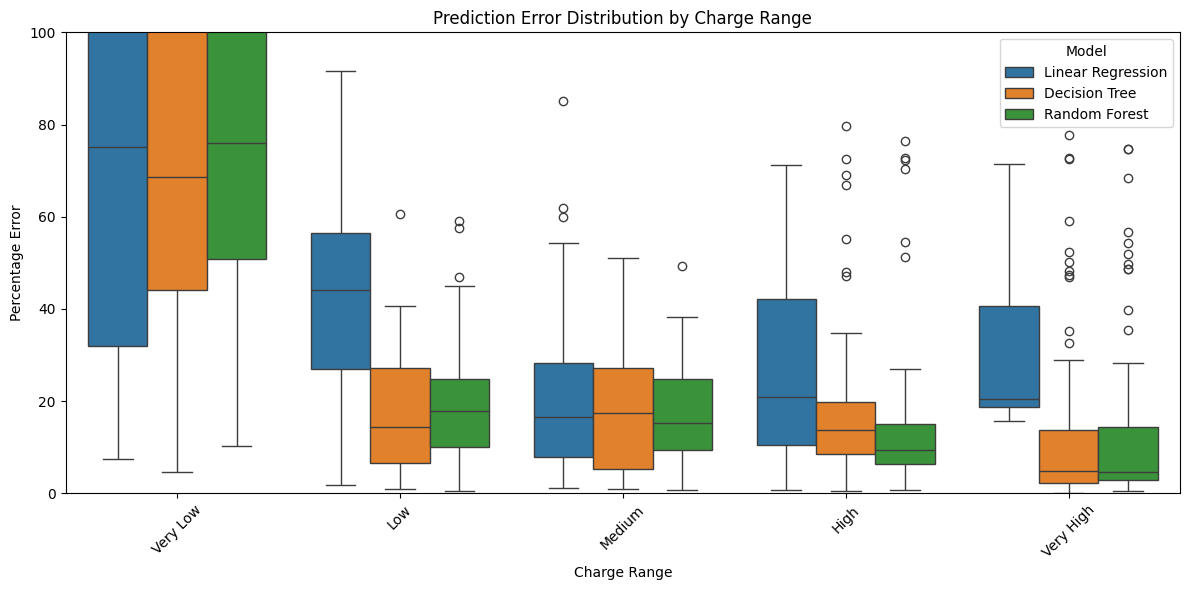


Mean Percentage Error by Charge Range:
              Linear Regression  Decision Tree  Random Forest
Charge Range                                                 
Very Low                  89.35          76.21          82.44
Low                       43.89          18.78          19.52
Medium                    22.05          19.24          17.42
High                      26.76          19.45          16.09
Very High                 29.22          14.81          14.85


/var/folders/43/25gq3lgs5gb321_snh3w2sb40000gn/T/ipykernel_1327/126139370.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_errors = error_data.groupby('Charge Range').mean().round(2)


In [7]:
# Create bins for actual charges
bins = pd.qcut(y, q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

# Calculate absolute percentage error for each model
percentage_errors = {}
for name, pred in predictions.items():
    percentage_errors[name] = abs((y_test - pred) / y) * 100

# Create box plots for percentage errors by charge range
error_data = pd.DataFrame(percentage_errors)
error_data['Charge Range'] = bins

plt.figure(figsize=(12, 6))
sns.boxplot(data=error_data.melt(id_vars=['Charge Range'], 
                                var_name='Model', 
                                value_name='Percentage Error'),
            x='Charge Range', 
            y='Percentage Error', 
            hue='Model')
plt.title('Prediction Error Distribution by Charge Range')
plt.xticks(rotation=45)
plt.ylim(0, 100)  # Limit y-axis to 0-100% for better visualization
plt.tight_layout()
plt.show()

# Calculate mean percentage error by charge range
mean_errors = error_data.groupby('Charge Range').mean().round(2)
print("\nMean Percentage Error by Charge Range:")
print(mean_errors)


🏆 THE WINNING MODEL: Random Forest 🏆
Final Accuracy (R2): 0.9026
Final Error (RMSE): 4230.9004


/var/folders/43/25gq3lgs5gb321_snh3w2sb40000gn/T/ipykernel_1327/677941968.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='R2', data=metrics_df, palette=colors)


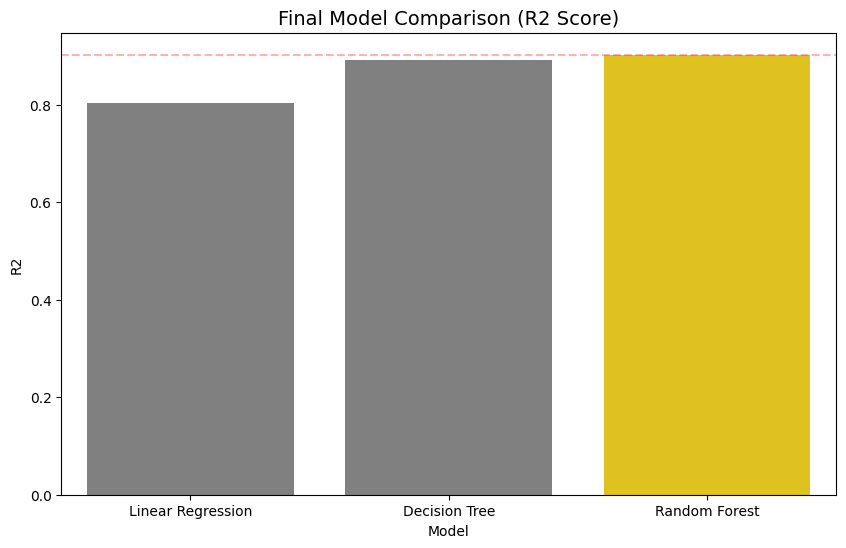

In [17]:
# پیدا کردن مدل با بالاترین R2
best_model_r2 = metrics_df.loc[metrics_df['R2'].idxmax()]

print("="*40)
print(f"🏆 THE WINNING MODEL: {best_model_r2['Model']} 🏆")
print("="*40)
print(f"Final Accuracy (R2): {best_model_r2['R2']:.4f}")
print(f"Final Error (RMSE): {best_model_r2['RMSE']:.4f}")
print("="*40)

plt.figure(figsize=(10, 6))
colors = ['grey' if x != metrics_df['R2'].max() else 'gold' for x in metrics_df['R2']]
sns.barplot(x='Model', y='R2', data=metrics_df, palette=colors)

plt.title('Final Model Comparison (R2 Score)', fontsize=14)
plt.axhline(y=metrics_df['R2'].max(), color='red', linestyle='--', alpha=0.3) # خط رکورد
plt.show()

## 6. Conclusion

Based on the evaluation metrics and visualizations above, we can conclude:

1. **Overall Performance**: 
   - Compare the RMSE and R² scores across models
   - Identify which model performs best overall

2. **Prediction Accuracy**:
   - Analyze how well each model predicts across different charge ranges
   - Note any systematic biases in predictions

3. **Feature Importance**:
   - Identify the most influential features for predicting insurance charges
   - Compare feature importance between Decision Tree and Random Forest models

4. **Model Selection**:
   - Recommend the best model for deployment
   - Note any trade-offs between model complexity and performance
